# 05 — Random Forest para Previsão de Séries Temporais

**Dissertação**: Análise Comparativa de Algoritmos de Regressão para Previsão em Séries Temporais  
**Autora**: Luana Gomes de Souza  
**Etapa**: OE1 + OE2 — Modelos baseados em árvores de decisão

---
### Diferença fundamental em relação aos modelos anteriores

Os modelos anteriores (SARIMA, Holt-Winters, SES) operam **nativamente no domínio temporal** —
recebem a série e modelam dependências temporais diretamente.

O Random Forest é um modelo **supervisionado tabular** — não entende sequências por construção.
Para aplicá-lo a séries temporais, é necessário transformar a série em um problema de regressão
supervisionada por meio de **engenharia de features temporais** (seção 2.3 da dissertação).

### Features construídas
Para cada passo de previsão, o modelo recebe:
- **Lags**: valores passados `y[t-1], y[t-2], ..., y[t-L]`
- **Estatísticas de janela móvel**: média e desvio padrão dos últimos L valores
- **Lag sazonal**: `y[t-12]` — valor do mesmo mês do ano anterior
- **Lag sazonal duplo**: `y[t-24]` — dois anos atrás (quando disponível)

### Estratégia de previsão multi-passo
Para prever H=18 passos à frente, usamos **recursiva direta**:
a previsão do passo h alimenta os lags do passo h+1.
Isso é a abordagem padrão para Random Forest em séries temporais.

## 1. Imports e configurações

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
import time
import json
from pathlib import Path
from datetime import datetime
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')

import sys

_root = Path.cwd().resolve()
for _candidate in (_root, *_root.parents):
    if (_candidate / 'src' / 'config.py').is_file():
        if str(_candidate) not in sys.path:
            sys.path.insert(0, str(_candidate))
        break

from src.config import (
    DATA_DIR,
    H,
    MIN_TRAIN,
    N_ORIGINS,
    PILOT_N,
    PROJECT_ROOT,
    RESULT_DIR,
    SEASON,
    SEED,
    verify_data_files,
)

RESULT_DIR.mkdir(parents=True, exist_ok=True)
verify_data_files()
print(f'PROJECT_ROOT = {PROJECT_ROOT}')
print(f'DATA_DIR       = {DATA_DIR}  OK')
print(f'RESULT_DIR     = {RESULT_DIR}')

# ── Configuração do Random Forest ────────────────────────────────────────────
N_LAGS       = 12   # número de lags como features
N_ESTIMATORS = 100  # árvores no ensemble
MAX_DEPTH    = None # sem limite — controlado por min_samples_leaf
MIN_SAMPLES_LEAF = 2

np.random.seed(SEED)
print('Configuração carregada OK')
print(f'  Lags            : {N_LAGS}')
print(f'  Árvores (n_est) : {N_ESTIMATORS}')
print(f'  Min samples leaf: {MIN_SAMPLES_LEAF}')

PROJECT_ROOT = C:\Users\Usuario\Desktop\Mestrado\Mestrado - aula\dissertação\autopred
DATA_DIR       = C:\Users\Usuario\Desktop\Mestrado\Mestrado - aula\dissertação\autopred\data\raw  OK
RESULT_DIR     = C:\Users\Usuario\Desktop\Mestrado\Mestrado - aula\dissertação\autopred\results
Configuração carregada OK
  Lags            : 12
  Árvores (n_est) : 100
  Min samples leaf: 2


## 2. Funções base (pipeline padrão)

In [7]:
from src.m4_io import load_m4_monthly, sample_pilot_ids

def make_rolling_windows(series, horizon, min_train, n_origins):
    n = len(series)
    if n < min_train + horizon:
        return []
    last_origin  = n - horizon
    first_origin = min_train
    if last_origin <= first_origin:
        return []
    origins = np.linspace(first_origin, last_origin, n_origins, dtype=int).tolist()
    origins = sorted(set(origins))
    return [
        {'origin': o, 'train': series[:o], 'test': series[o:o+horizon]}
        for o in origins if len(series[o:o+horizon]) == horizon
    ]

def calc_mape(y_true, y_pred):
    mask = y_true != 0
    if mask.sum() == 0:
        return np.nan
    return float(np.mean(np.abs((y_true[mask]-y_pred[mask])/y_true[mask]))*100)

def calc_metrics(y_true, y_pred):
    return {
        'mape': calc_mape(y_true, y_pred),
        'mae' : float(mean_absolute_error(y_true, y_pred)),
        'r2'  : float(r2_score(y_true, y_pred))
    }

print('Funções base OK')

Funções base OK


## 3. Carregamento e piloto

In [8]:
import sys
import numpy as np
from pathlib import Path

_root = Path.cwd().resolve()
for _candidate in (_root, *_root.parents):
    if (_candidate / 'src' / 'config.py').is_file():
        if str(_candidate) not in sys.path:
            sys.path.insert(0, str(_candidate))
        break

from src.config import DATA_DIR, PILOT_N, SEED

if 'load_m4_monthly' not in globals():
    raise RuntimeError(
        'Execute antes a célula "## 2. Funções base (pipeline padrão)".'
    )

# Só as séries do piloto — evita melt do M4 inteiro (~48k séries) na RAM
pilot_ids = sample_pilot_ids(DATA_DIR, PILOT_N, SEED)
train_df, test_df = load_m4_monthly(DATA_DIR, series_ids=pilot_ids)
train_pilot = train_df.copy()
print(f'Piloto: {PILOT_N} séries | {len(train_pilot):,} linhas train | {len(test_df):,} linhas test')

Piloto: 200 séries | 42,600 linhas train | 3,600 linhas test


## 4. Engenharia de features temporais

Esta é a etapa que diferencia modelos tabulares de modelos nativamente temporais.
Cada observação `y[t]` vira uma linha com colunas de features derivadas do histórico.

In [10]:
def build_features(series, n_lags=N_LAGS, season=SEASON):
    """
    Constrói matriz de features a partir de uma série temporal.

    Features por linha (passo t):
      - lag_1 .. lag_L        : valores passados y[t-1] .. y[t-L]
      - roll_mean_L           : média dos últimos L valores
      - roll_std_L            : desvio padrão dos últimos L valores
      - lag_season            : y[t-12] — mesmo mês ano anterior
      - lag_season2           : y[t-24] — dois anos atrás (NaN se indisponível)

    Retorna X (features) e y (target) como arrays numpy.
    Linhas com NaN nos lags são removidas.
    """
    n      = len(series)
    lag_cols = {f'lag_{i}': np.full(n, np.nan) for i in range(1, n_lags+1)}

    for i in range(1, n_lags+1):
        lag_cols[f'lag_{i}'][i:] = series[:-i]

    df = pd.DataFrame(lag_cols)
    df['roll_mean'] = df[[f'lag_{i}' for i in range(1, n_lags+1)]].mean(axis=1)
    df['roll_std']  = df[[f'lag_{i}' for i in range(1, n_lags+1)]].std(axis=1)

    # Lags sazonais (.loc — compatível com pandas 3 / Copy-on-Write)
    df['lag_season']  = np.nan
    df['lag_season2'] = np.nan
    if n > season:
        df.loc[season:, 'lag_season'] = series[:-season]
    if n > 2 * season:
        df.loc[2 * season:, 'lag_season2'] = series[:-2 * season]

    df['y'] = series
    feature_cols = [f'lag_{i}' for i in range(1, n_lags + 1)] + [
        'roll_mean', 'roll_std', 'lag_season',
    ]
    if n > 2 * season:
        feature_cols.append('lag_season2')

    df = df.dropna(subset=feature_cols)

    X = df[feature_cols].values
    y = df['y'].values
    return X, y, feature_cols


# Teste com série sintética
ex = np.tile([100,105,110,115,120,125,120,115,110,105,100,95], 3).astype(float)
X_ex, y_ex, feat_names = build_features(ex)
print(f'Série de {len(ex)} obs → {X_ex.shape[0]} amostras supervisionadas')
print(f'Features ({len(feat_names)}): {feat_names}')
if len(X_ex) == 0:
    raise ValueError(
        f'Nenhuma amostra após dropna — série precisa de > {max(N_LAGS, 2*SEASON)} obs '
        f'(tem {len(ex)}).'
    )
print(f'Primeira amostra X: {X_ex[0].round(2)}')
print(f'Primeiro target y : {y_ex[0]}')

Série de 36 obs → 24 amostras supervisionadas
Features (16): ['lag_1', 'lag_2', 'lag_3', 'lag_4', 'lag_5', 'lag_6', 'lag_7', 'lag_8', 'lag_9', 'lag_10', 'lag_11', 'lag_12', 'roll_mean', 'roll_std', 'lag_season', 'lag_season2']
Primeira amostra X: [ 95.   100.   105.   110.   115.   120.   125.   120.   115.   110.
 105.   100.   110.     9.29 100.      nan]
Primeiro target y : 100.0


## 5. Previsão recursiva multi-passo

O Random Forest produz uma previsão por vez (h=1).  
Para H=18, iteramos: a previsão do passo h entra como lag nos passos seguintes.

In [11]:
def predict_recursive(model, train, horizon, n_lags=N_LAGS, season=SEASON):
    """
    Previsão recursiva multi-passo com Random Forest.
    A cada passo h, a previsão é adicionada ao histórico
    e usada como feature para o passo h+1.
    """
    history = list(train.copy())
    preds   = []

    for h in range(horizon):
        n = len(history)

        # Constrói features para o próximo passo
        lags = [history[n-i] for i in range(1, n_lags+1)]

        roll_mean = np.mean(lags)
        roll_std  = np.std(lags, ddof=1) if len(lags) > 1 else 0.0

        lag_s  = history[n - season]      if n >= season    else history[0]
        lag_s2 = history[n - 2*season]    if n >= 2*season  else np.nan

        x = np.array(lags + [roll_mean, roll_std, lag_s, lag_s2],
                     dtype=float).reshape(1, -1)

        # Substitui NaN por 0 (lag_season2 ausente no início)
        x = np.nan_to_num(x, nan=0.0)

        pred = model.predict(x)[0]
        preds.append(pred)
        history.append(pred)   # alimenta o próximo passo

    return np.array(preds)


# Teste rápido
rf_test = RandomForestRegressor(n_estimators=10, random_state=SEED)
rf_test.fit(X_ex, y_ex)
pred_test = predict_recursive(rf_test, ex, horizon=6)
print(f'Previsão recursiva (6 passos): {pred_test.round(2)}')

Previsão recursiva (6 passos): [ 99.5 105.  110.  116.  119.5 124.5]


## 6. Modelo Random Forest completo

Encapsula treino + previsão em uma função compatível com o pipeline padrão.

In [12]:
def model_random_forest(train, horizon,
                        n_lags=N_LAGS, season=SEASON,
                        n_estimators=N_ESTIMATORS,
                        min_samples_leaf=MIN_SAMPLES_LEAF):
    """
    Random Forest para previsão de séries temporais.
    1. Constrói features supervisionadas a partir do treino
    2. Treina RF na janela de treino
    3. Prevê H passos recursivamente
    Fallback para média histórica se treino insuficiente.
    """
    # Precisa de pelo menos n_lags + season observações para ter amostras válidas
    min_needed = max(n_lags, season) + 1
    if len(train) < min_needed:
        return np.full(horizon, np.mean(train))

    X, y, _ = build_features(train, n_lags, season)

    if len(X) < 2:
        return np.full(horizon, np.mean(train))

    rf = RandomForestRegressor(
        n_estimators     = n_estimators,
        max_depth        = MAX_DEPTH,
        min_samples_leaf = min_samples_leaf,
        random_state     = SEED,
        n_jobs           = -1    # usa todos os cores disponíveis
    )
    rf.fit(X, y)
    return predict_recursive(rf, train, horizon, n_lags, season)


# Verificação
ex_train = np.tile([100,105,110,115,120,125,120,115,110,105,100,95], 3).astype(float)
ex_pred  = model_random_forest(ex_train, horizon=H)
print(f'RF — previsão {H} passos:')
print(f'  {ex_pred.round(1)}')
print(f'  Constante? {np.allclose(ex_pred, ex_pred[0])}')

RF — previsão 18 passos:
  [ 99.3 105.  109.7 115.7 120.8 123.3 120.4 115.4 109.7 104.8  99.5  97.3
  99.3 105.  109.8 115.7 120.9 123.3]
  Constante? False


## 7. Execução do pipeline

> **Tempo esperado**: 2–8 minutos para 200 séries.  
> `n_jobs=-1` usa todos os cores — o progresso é impresso a cada 50 séries.

In [13]:
def run_pipeline(train_df, horizon, min_train, n_origins, model_name, predict_fn):
    records = []
    ids     = train_df['unique_id'].unique()
    total   = len(ids)
    for i, uid in enumerate(ids):
        if (i+1) % 50 == 0 or i == 0:
            print(f'  [{i+1}/{total}] {uid}')
        values  = train_df[train_df['unique_id']==uid]['y'].values.astype(float)
        windows = make_rolling_windows(values, horizon, min_train, n_origins)
        if not windows:
            records.append({'unique_id':uid,'model':model_name,'origin':None,
                            'n_train':None,'mape':None,'mae':None,'r2':None,
                            'exec_time_s':None,'status':'SKIP_SHORT'})
            continue
        for win in windows:
            t0 = time.perf_counter()
            try:
                pred    = predict_fn(win['train'], horizon)
                metrics = calc_metrics(win['test'], pred)
                status  = 'OK'
            except Exception as e:
                metrics = {'mape':None,'mae':None,'r2':None}
                status  = f'ERROR: {str(e)[:80]}'
            records.append({
                'unique_id'  : uid, 'model': model_name,
                'origin'     : win['origin'], 'n_train': len(win['train']),
                **metrics,
                'exec_time_s': time.perf_counter()-t0,
                'status'     : status
            })
    return pd.DataFrame(records)


print(f'Rodando Random Forest em {PILOT_N} séries...')
t_start = time.time()

results_rf = run_pipeline(
    train_df   = train_pilot,
    horizon    = H,
    min_train  = MIN_TRAIN,
    n_origins  = N_ORIGINS,
    model_name = 'random_forest',
    predict_fn = model_random_forest
)

elapsed = time.time() - t_start
ok_n    = (results_rf['status'] == 'OK').sum()
err_n   = results_rf['status'].str.startswith('ERROR', na=False).sum()
skip_n  = (results_rf['status'] == 'SKIP_SHORT').sum()

print(f'\nConcluído em {elapsed:.1f}s ({elapsed/60:.1f} min)')
print(f'  OK           : {ok_n} janelas')
print(f'  Skip (curta) : {skip_n}')
print(f'  Erros        : {err_n}')
print(f'  Taxa sucesso : {100*ok_n/(ok_n+err_n+skip_n):.1f}%')

Rodando Random Forest em 200 séries...
  [1/200] M10288
  [50/200] M21209
  [100/200] M32071
  [150/200] M40980
  [200/200] M9633

Concluído em 203.6s (3.4 min)
  OK           : 600 janelas
  Skip (curta) : 0
  Erros        : 0
  Taxa sucesso : 100.0%


## 8. Resultados e comparação acumulada

In [14]:
ok_rf = results_rf[results_rf['status'] == 'OK'].copy()

by_series_rf = (
    ok_rf.groupby('unique_id')[['mape','mae','r2','exec_time_s']]
    .median().reset_index()
)

print('=== Desempenho Random Forest ===')
print(by_series_rf[['mape','mae','r2']].describe().round(3).to_string())
print(f'\nMAPE mediano = {by_series_rf["mape"].median():.4f}%')
print(f'MAE  mediano = {by_series_rf["mae"].median():.4f}')
print(f'R²   mediano = {by_series_rf["r2"].median():.4f}')
print(f'Tempo mediano= {by_series_rf["exec_time_s"].median():.4f}s')

# Tabela acumulada
prev_path = RESULT_DIR / 'tabela_acumulada_nb04b_sarima_auto.csv'
if prev_path.exists():
    prev = pd.read_csv(prev_path, index_col=0)
    rf_row = pd.DataFrame([{
        'MAPE (%)' : round(by_series_rf['mape'].median(), 4),
        'MAE'      : round(by_series_rf['mae'].median(),  4),
        'R²'       : round(by_series_rf['r2'].median(),   4),
        'Tempo (s)': round(by_series_rf['exec_time_s'].median(), 4),
    }], index=['Random Forest'])
    summary = pd.concat([prev, rf_row]).sort_values('MAPE (%)')
else:
    summary = pd.DataFrame([{
        'MAPE (%)' : round(by_series_rf['mape'].median(), 4),
        'MAE'      : round(by_series_rf['mae'].median(),  4),
        'R²'       : round(by_series_rf['r2'].median(),   4),
        'Tempo (s)': round(by_series_rf['exec_time_s'].median(), 4),
    }], index=['Random Forest'])

print('\n=== Comparação acumulada ===')
print(summary.to_string())
summary.to_csv(RESULT_DIR / 'tabela_acumulada_nb05_rf.csv')
print('\nTabela salva em results/tabela_acumulada_nb05_rf.csv')

=== Desempenho Random Forest ===
          mape       mae       r2
count  200.000   200.000  200.000
mean    16.607   642.440   -1.944
std     21.224   973.107    2.456
min      0.855    12.234  -13.481
25%      3.576   137.742   -2.753
50%     10.586   341.668   -1.092
75%     21.491   704.368   -0.241
max    157.492  7438.618    0.928

MAPE mediano = 10.5861%
MAE  mediano = 341.6680
R²   mediano = -1.0925
Tempo mediano= 0.3364s

=== Comparação acumulada ===
                   MAPE (%)       MAE      R²  Tempo (s)
Holt-Winters         8.2606  256.0183 -1.0642     0.1852
Persistência         8.6992  274.1667 -1.2684     0.0004
SES                  8.7764  253.5196 -1.1898     0.0038
SARIMA auto (AIC)    9.1184  266.3902 -1.2678     0.2127
SARIMA heurístico   10.0628  284.7858 -2.0551     0.0990
Random Forest       10.5861  341.6680 -1.0925     0.3364
Sazonal ingênuo     11.0601  316.8889 -2.1744     0.0004
Média histórica     18.5971  589.9421 -6.4779     0.0004

Tabela salva em result

## 9. Importância de features — base para SHAP

O Random Forest fornece importância de features nativa (impurity-based).  
Este resultado antecipa a análise SHAP do OE4 e é diretamente citável na dissertação  
para a seção 2.3: *'a importância de características temporais defasadas'*.

In [15]:
# Treina RF na série completa de um exemplo para extrair importâncias
ex_uid  = by_series_rf.sort_values('mape').iloc[len(by_series_rf)//2]['unique_id']
ex_vals = train_pilot[train_pilot['unique_id']==ex_uid]['y'].values.astype(float)

X_imp, y_imp, feat_names_imp = build_features(ex_vals)
rf_imp = RandomForestRegressor(
    n_estimators=N_ESTIMATORS, random_state=SEED, n_jobs=-1
)
rf_imp.fit(X_imp, y_imp)
importances = rf_imp.feature_importances_

# Agrega importâncias em categorias
imp_df = pd.DataFrame({
    'feature'   : feat_names_imp,
    'importance': importances
}).sort_values('importance', ascending=False)

print(f'Série exemplo: {ex_uid}')
print('\nTop 10 features por importância (impurity):')
print(imp_df.head(10).to_string(index=False))

Série exemplo: M44154

Top 10 features por importância (impurity):
  feature  importance
    lag_2    0.207720
roll_mean    0.188374
    lag_1    0.129252
    lag_4    0.128521
    lag_3    0.069303
    lag_5    0.069221
   lag_12    0.041147
    lag_7    0.039776
    lag_8    0.029972
    lag_6    0.029774


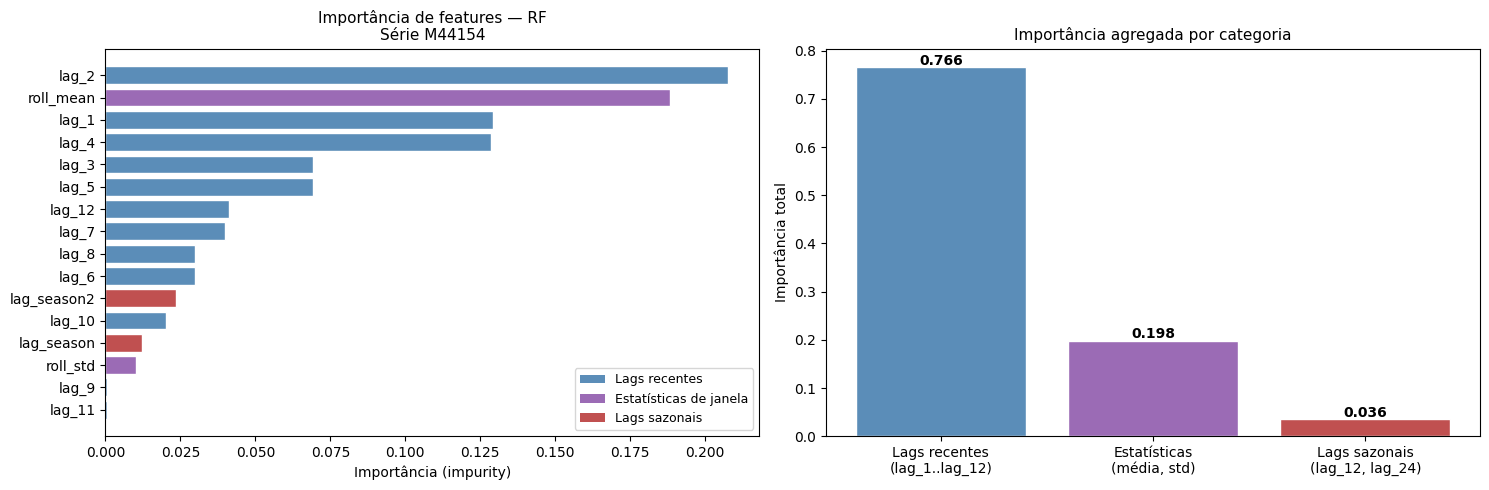

Figura salva em results/


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Gráfico 1 — importância por feature
colors_imp = ['#C05050' if 'season' in f else
               '#9B6BB5' if 'roll'   in f else
               '#5B8DB8'
               for f in imp_df['feature']]
axes[0].barh(imp_df['feature'], imp_df['importance'],
             color=colors_imp, edgecolor='white')
axes[0].set_title(f'Importância de features — RF\nSérie {ex_uid}', fontsize=11)
axes[0].set_xlabel('Importância (impurity)')
axes[0].invert_yaxis()

# Legenda manual
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#5B8DB8', label='Lags recentes'),
    Patch(facecolor='#9B6BB5', label='Estatísticas de janela'),
    Patch(facecolor='#C05050', label='Lags sazonais'),
]
axes[0].legend(handles=legend_elements, fontsize=9)

# Gráfico 2 — importância agregada por categoria
cat_imp = {
    'Lags recentes\n(lag_1..lag_12)': imp_df[imp_df['feature'].str.startswith('lag_') &
                                              ~imp_df['feature'].str.contains('season')]['importance'].sum(),
    'Estatísticas\n(média, std)'    : imp_df[imp_df['feature'].str.startswith('roll')]['importance'].sum(),
    'Lags sazonais\n(lag_12, lag_24)': imp_df[imp_df['feature'].str.contains('season')]['importance'].sum(),
}
axes[1].bar(cat_imp.keys(), cat_imp.values(),
            color=['#5B8DB8','#9B6BB5','#C05050'], edgecolor='white')
axes[1].set_title('Importância agregada por categoria', fontsize=11)
axes[1].set_ylabel('Importância total')
for i, (k, v) in enumerate(cat_imp.items()):
    axes[1].text(i, v + 0.005, f'{v:.3f}', ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig(RESULT_DIR / 'fig_rf_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figura salva em results/')

## 10. Boxplot comparativo acumulado

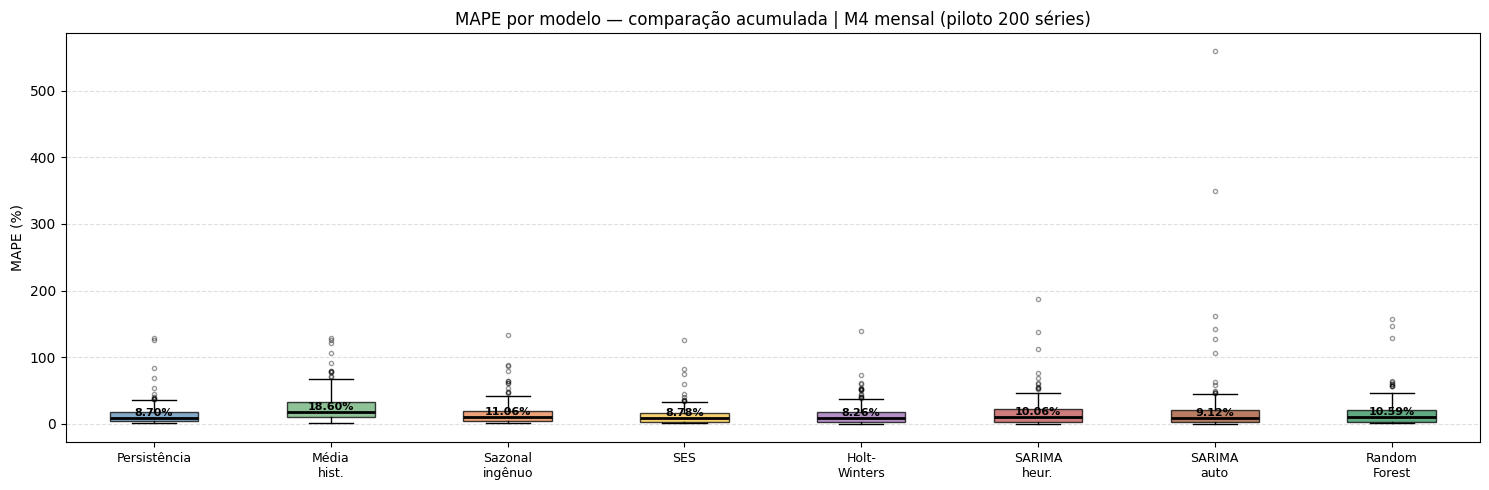

In [17]:
# Carrega dados anteriores
dfs = []
for fname, model_col in [
    ('results_nb02_by_series.csv',               None),
    ('results_ses_by_series.csv',                'ses'),
    ('results_sarima_heuristic_by_series.csv',   'sarima_heuristic'),
    ('results_sarima_auto_by_series.csv',        'sarima_auto'),
]:
    path = RESULT_DIR / fname
    if path.exists():
        df = pd.read_csv(path)
        if 'model' not in df.columns and model_col:
            df['model'] = model_col
        dfs.append(df)

rf_plot = by_series_rf.copy()
rf_plot['model'] = 'random_forest'
dfs.append(rf_plot)
all_df = pd.concat(dfs, ignore_index=True)

order_plot = ['persistence','mean','seasonal_naive','ses',
              'holt_winters','sarima_heuristic','sarima_auto','random_forest']
name_map   = {
    'persistence'     : 'Persistência',
    'mean'            : 'Média\nhist.',
    'seasonal_naive'  : 'Sazonal\ningênuo',
    'ses'             : 'SES',
    'holt_winters'    : 'Holt-\nWinters',
    'sarima_heuristic': 'SARIMA\nheur.',
    'sarima_auto'     : 'SARIMA\nauto',
    'random_forest'   : 'Random\nForest',
}
colors_plot = ['#5B8DB8','#6BAE75','#E8834E','#F5C242',
               '#9B6BB5','#C05050','#A0522D','#2E8B57']

order_present = [m for m in order_plot if m in all_df['model'].unique()]
data_list     = [all_df[all_df['model']==m]['mape'].dropna() for m in order_present]

fig, ax = plt.subplots(figsize=(15, 5))
bp = ax.boxplot(
    data_list, patch_artist=True,
    medianprops=dict(color='black', linewidth=2),
    flierprops=dict(marker='o', markersize=3, alpha=0.4)
)
for patch, color in zip(bp['boxes'], colors_plot[:len(order_present)]):
    patch.set_facecolor(color)
    patch.set_alpha(0.75)

ax.set_xticks(range(1, len(order_present)+1))
ax.set_xticklabels([name_map[m] for m in order_present], fontsize=9)
ax.set_ylabel('MAPE (%)')
ax.set_title('MAPE por modelo — comparação acumulada | M4 mensal (piloto 200 séries)')
ax.grid(axis='y', linestyle='--', alpha=0.4)
for i, d in enumerate(data_list):
    ax.text(i+1, d.median(), f'{d.median():.2f}%',
            ha='center', va='bottom', fontsize=8, fontweight='bold')

plt.tight_layout()
plt.savefig(RESULT_DIR / 'fig_mape_acumulado_nb05.png', dpi=150, bbox_inches='tight')
plt.show()

## 11. Visualização — exemplo de previsão

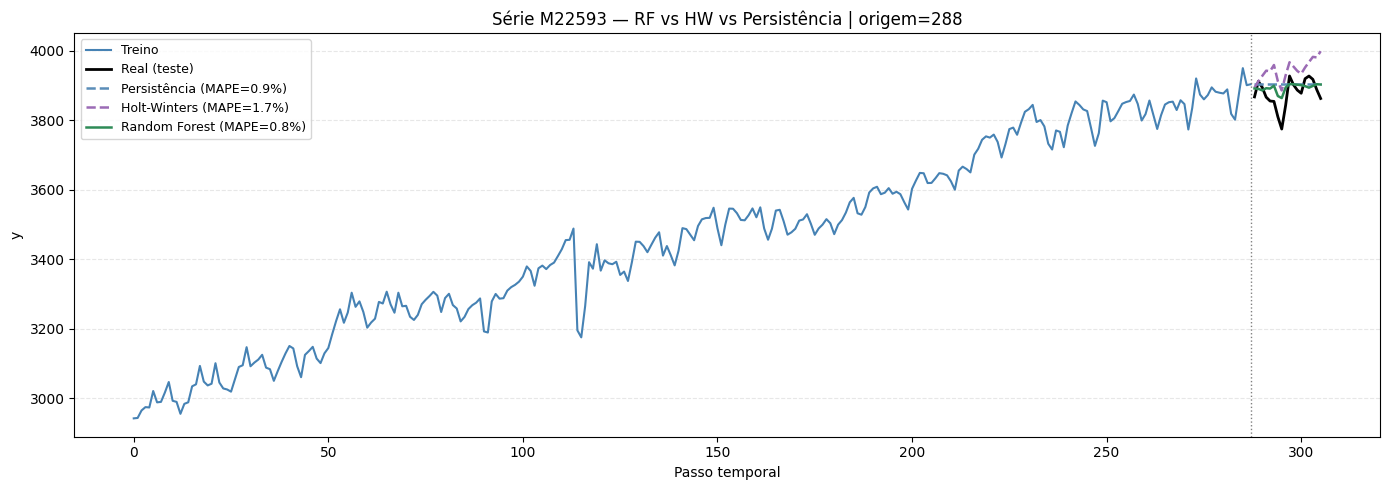

In [18]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

def holt_winters(train, horizon, season=12):
    n = len(train)
    if n < 2*season:
        return np.full(horizon, train[-1])
    best_model, best_aic = None, np.inf
    for stype in (['add'] + (['mul'] if np.all(train > 0) else [])):
        try:
            m = ExponentialSmoothing(
                train, trend='add', seasonal=stype,
                seasonal_periods=season,
                initialization_method='estimated'
            ).fit(optimized=True)
            if m.aic < best_aic:
                best_aic, best_model = m.aic, m
        except Exception:
            continue
    return best_model.forecast(horizon) if best_model else np.full(horizon, train[-1])


# Série com melhor desempenho do RF
ex_uid2  = by_series_rf.sort_values('mape').iloc[0]['unique_id']
ex_vals2 = train_pilot[train_pilot['unique_id']==ex_uid2]['y'].values.astype(float)
ex_wins2 = make_rolling_windows(ex_vals2, H, MIN_TRAIN, N_ORIGINS)
win      = ex_wins2[-1]

preds_comp = {
    'Persistência' : (np.full(H, win['train'][-1]),           '#5B8DB8', '--'),
    'Holt-Winters' : (holt_winters(win['train'], H),          '#9B6BB5', '--'),
    'Random Forest': (model_random_forest(win['train'], H),   '#2E8B57', '-'),
}

fig, ax = plt.subplots(figsize=(14, 5))
x_tr = range(len(win['train']))
x_te = range(len(win['train']), len(win['train'])+H)

ax.plot(x_tr, win['train'], color='steelblue', linewidth=1.5, label='Treino')
ax.plot(x_te, win['test'],  color='black',     linewidth=2,   label='Real (teste)')
ax.axvline(len(win['train'])-1, color='gray', linestyle=':', linewidth=1)

for label, (pred, color, ls) in preds_comp.items():
    mape_val = calc_mape(win['test'], pred)
    ax.plot(x_te, pred, color=color, linewidth=1.8, linestyle=ls,
            label=f'{label} (MAPE={mape_val:.1f}%)')

ax.set_title(f'Série {ex_uid2} — RF vs HW vs Persistência | origem={win["origin"]}')
ax.set_xlabel('Passo temporal')
ax.set_ylabel('y')
ax.legend(fontsize=9)
ax.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.savefig(RESULT_DIR / f'fig_rf_exemplo_{ex_uid2}.png', dpi=150, bbox_inches='tight')
plt.show()

## 12. Salvando artefatos

In [19]:
results_rf.to_csv(RESULT_DIR / 'results_rf_by_window.csv', index=False)
rf_plot.to_csv(RESULT_DIR / 'results_rf_by_series.csv', index=False)
imp_df.to_csv(RESULT_DIR / 'rf_feature_importance_example.csv', index=False)

run_log = {
    'timestamp'       : datetime.now().isoformat(),
    'notebook'        : '05_random_forest',
    'model'           : 'random_forest',
    'n_lags'          : N_LAGS,
    'n_estimators'    : N_ESTIMATORS,
    'min_samples_leaf': MIN_SAMPLES_LEAF,
    'dataset'         : 'M4_Monthly',
    'pilot_n'         : PILOT_N,
    'seed'            : SEED,
    'horizon_H'       : H,
    'n_ok'            : int(ok_n),
    'n_errors'        : int(err_n),
    'taxa_sucesso'    : round(100*ok_n/(ok_n+err_n+skip_n), 2),
    'mape_median'     : round(float(by_series_rf['mape'].median()), 4),
    'mae_median'      : round(float(by_series_rf['mae'].median()),  4),
    'r2_median'       : round(float(by_series_rf['r2'].median()),   4),
    'time_median_s'   : round(float(by_series_rf['exec_time_s'].median()), 4),
}

with open(RESULT_DIR / 'run_log_rf.json', 'w') as f:
    json.dump(run_log, f, indent=2)

print('Artefatos salvos:')
print('  results_rf_by_window.csv')
print('  results_rf_by_series.csv')
print('  rf_feature_importance_example.csv')
print('  run_log_rf.json')
print()
print(json.dumps(run_log, indent=2))

Artefatos salvos:
  results_rf_by_window.csv
  results_rf_by_series.csv
  rf_feature_importance_example.csv
  run_log_rf.json

{
  "timestamp": "2026-05-23T11:02:06.612830",
  "notebook": "05_random_forest",
  "model": "random_forest",
  "n_lags": 12,
  "n_estimators": 100,
  "min_samples_leaf": 2,
  "dataset": "M4_Monthly",
  "pilot_n": 200,
  "seed": 42,
  "horizon_H": 18,
  "n_ok": 600,
  "n_errors": 0,
  "taxa_sucesso": 100.0,
  "mape_median": 10.5861,
  "mae_median": 341.668,
  "r2_median": -1.0925,
  "time_median_s": 0.3364
}


## 13. Resumo e próximos passos

---

### Posição do Random Forest na dissertação

| Aspecto | Observação |
|---|---|
| Engenharia de features | Necessária — diferencia de modelos nativamente temporais |
| Previsão multi-passo | Recursiva — erro se propaga a cada passo |
| Importância de features | Nativa (impurity) — base para análise SHAP |
| Robustez a outliers | Alta — particionamento isola observações atípicas |
| Custo computacional | Moderado — `n_jobs=-1` paraleliza |

### O que observar nos resultados
- Se RF superar HW em MAPE → modelos de árvore capturam não-linearidades úteis
- Se lag_season dominar importância → sazonalidade é o padrão principal
- Se roll_mean dominar → nível local é mais informativo que lags individuais

---

### Próximo notebook: `06_gradient_boosting.ipynb`
- Gradient Boosting (GBT) — abordagem sequencial vs paralela do RF
- Mesma engenharia de features para comparação justa
- Comparação RF vs GBT dentro da família de árvores